# Session 11: Optimizers and Learning-Rate Schedules

Runs the whole assignment top to bottom on the Session 9/10 model and data. Each section runs
`experiments/session11.py` as a subprocess, streams its output here and saves it to `runs/notebook/`.
Plots and CSVs go to `runs/session11/`.

| Section | Task | Time (plugged-in laptop) |
|---|---|---|
| adam | 1. Adam by hand vs PyTorch | ~1 min |
| bias | 2. Bias correction on/off | ~4 min |
| ratio | 3. Update-to-weight ratio per layer | ~4 min |
| schedule | 4. Cosine vs WSD, stopped at 200 | ~3 min |
| sweep | 5. LR sweep at widths 256/384/512/1024 | ~60-75 min (resumable) |

In [1]:
import os, subprocess, sys, time
from pathlib import Path
from IPython.display import Image, display

OUT = Path("runs/notebook"); OUT.mkdir(parents=True, exist_ok=True)
FIG = Path("runs/session11")
ENV = {**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUNBUFFERED": "1"}

def run(section, log_name, *extra):
    cmd = [sys.executable, "-m", "experiments.session11", "--section", section, *extra]
    t = time.time()
    with open(OUT / log_name, "w", encoding="utf-8") as f:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, encoding="utf-8", env=ENV)
        for line in p.stdout:
            print(line, end="")
            f.write(line)
        p.wait()
    print(f"\n[{section}: {(time.time() - t) / 60:.1f} min, saved {OUT / log_name}]")
    assert p.returncode == 0, f"{section} failed (exit {p.returncode})"

def show(name):
    path = FIG / name
    display(Image(filename=str(path))) if path.exists() else print(f"(no {path})")

## Task 1: Adam by hand, checked against PyTorch

In [2]:
run("adam", "s11_1_adam.txt")

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

1. ADAM BY HAND, CHECKED AGAINST PYTORCH (Task 1)
  one weight, w0 = 1.0, gradients [0.5, 0.4, 0.6, 0.45, 0.55], lr 0.001, betas (0.9, 0.999), eps 1e-08
  by hand: plain Python floats (fp64), train/adam_by_hand.py

    t      g          m           v     m_hat     v_hat        step  step/lr          w
    1   0.50   0.050000  0.00025000  0.500000  0.250000 -0.00100000  -1.0000   0.999000
    2   0.40   0.085000  0.00040975  0.447368  0.204977 -0.00098813  -0.9881   0.998012
    3   0.60   0.136500  0.00076934  0.503690  0.256703 -0.00099414  -0.9941   0.997018
    4   0.45   0.167850  0.00097107  0.488078  0.243132 -0.00098985  -0.9898   0.996028
    5   0.55   0.206065  0.00127260  0.503199  0.255030 -0.00099642  -0.9964   0.995031
  m_hat / sqrt(v_hat) stays near 1, so every step stays near lr while g ranges 0.40-0.60.

  The same five steps through torch.optim.AdamW (weight_decay=0, so it is plain Adam):
  PyTorch fp64 

## Task 2: Bias correction on vs off

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

2. BIAS CORRECTION ON vs OFF (Task 2)
  2a. One weight, 20 gradients (the notes' five, then ~0.5 +/- 0.05), lr 1e-3.
      Step size in units of lr. The ratio OFF/ON at the same step is (1 - b1^t) / sqrt(1 - b2^t).

                        ---- beta2 = 0.999 ----           ---- beta2 = 0.95 ----
     t       g        ON       OFF    factor           ON       OFF    factor   
     1  0.5000     1.000     3.162     3.162        1.000     0.447     0.447   
     2  0.4000     0.988     4.199     4.250        0.991     0.603     0.608   
     3  0.6000     0.994     4.921     4.950        0.991     0.711     0.718   
     4  0.4500     0.990     5.386     5.442        0.989     0.790     0.798   
     5  0.5500     0.996     5.776     5.797        0.994     0.855     0.861   
     6  0.5471     1.001     6.060     6.057        0.996     0.907     0.910   
     7  0.4302     0.991     6.188     6.245        0.991     0.941     

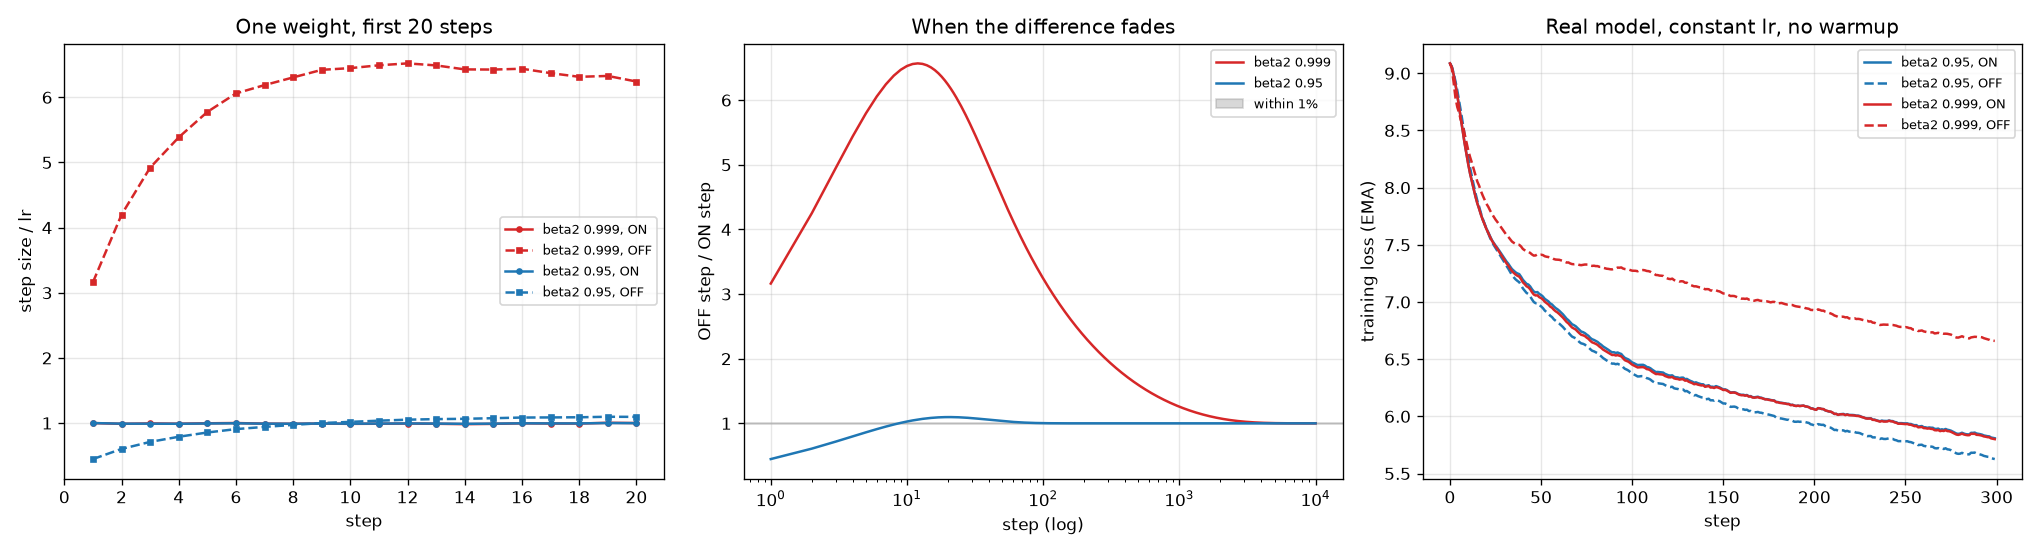

In [3]:
run("bias", "s11_2_bias.txt")
show("bias_correction.png")

## Task 3: Update-to-weight ratio for every layer

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

3. UPDATE-TO-WEIGHT RATIO FOR EVERY LAYER: when does warmup stop mattering? (Task 3)
  600 steps each, lr peak 0.001. Run A warms up over 100 steps; run B starts at the
  peak. After step 100 both follow the identical cosine. Same weights, same batches.
  ratio = ||w_after - w_before|| / ||w_before|| per parameter tensor, every step

  RUN warmup
    step        lr     loss     true    gnorm     val      ms    time
       0  1.00e-05   9.0867   9.0867    4.971  9.0895     229      1s
      50  5.10e-04   7.0809   7.0809    0.624       -     111      6s
     100  1.00e-03   6.2888   6.2888    0.567  6.3423     111     12s
     150  9.78e-04   5.9812   5.9812    0.519       -     112     17s
     200  9.14e-04   5.7495   5.7495    0.588  5.8073     111     23s
     250  8.15e-04   5.6337   5.6337    0.575       -     113     29s
     300  6.89e-04   5.4619   5.4619    0.498  5.4697     115     35s
     350  5.50e-04   5.4016

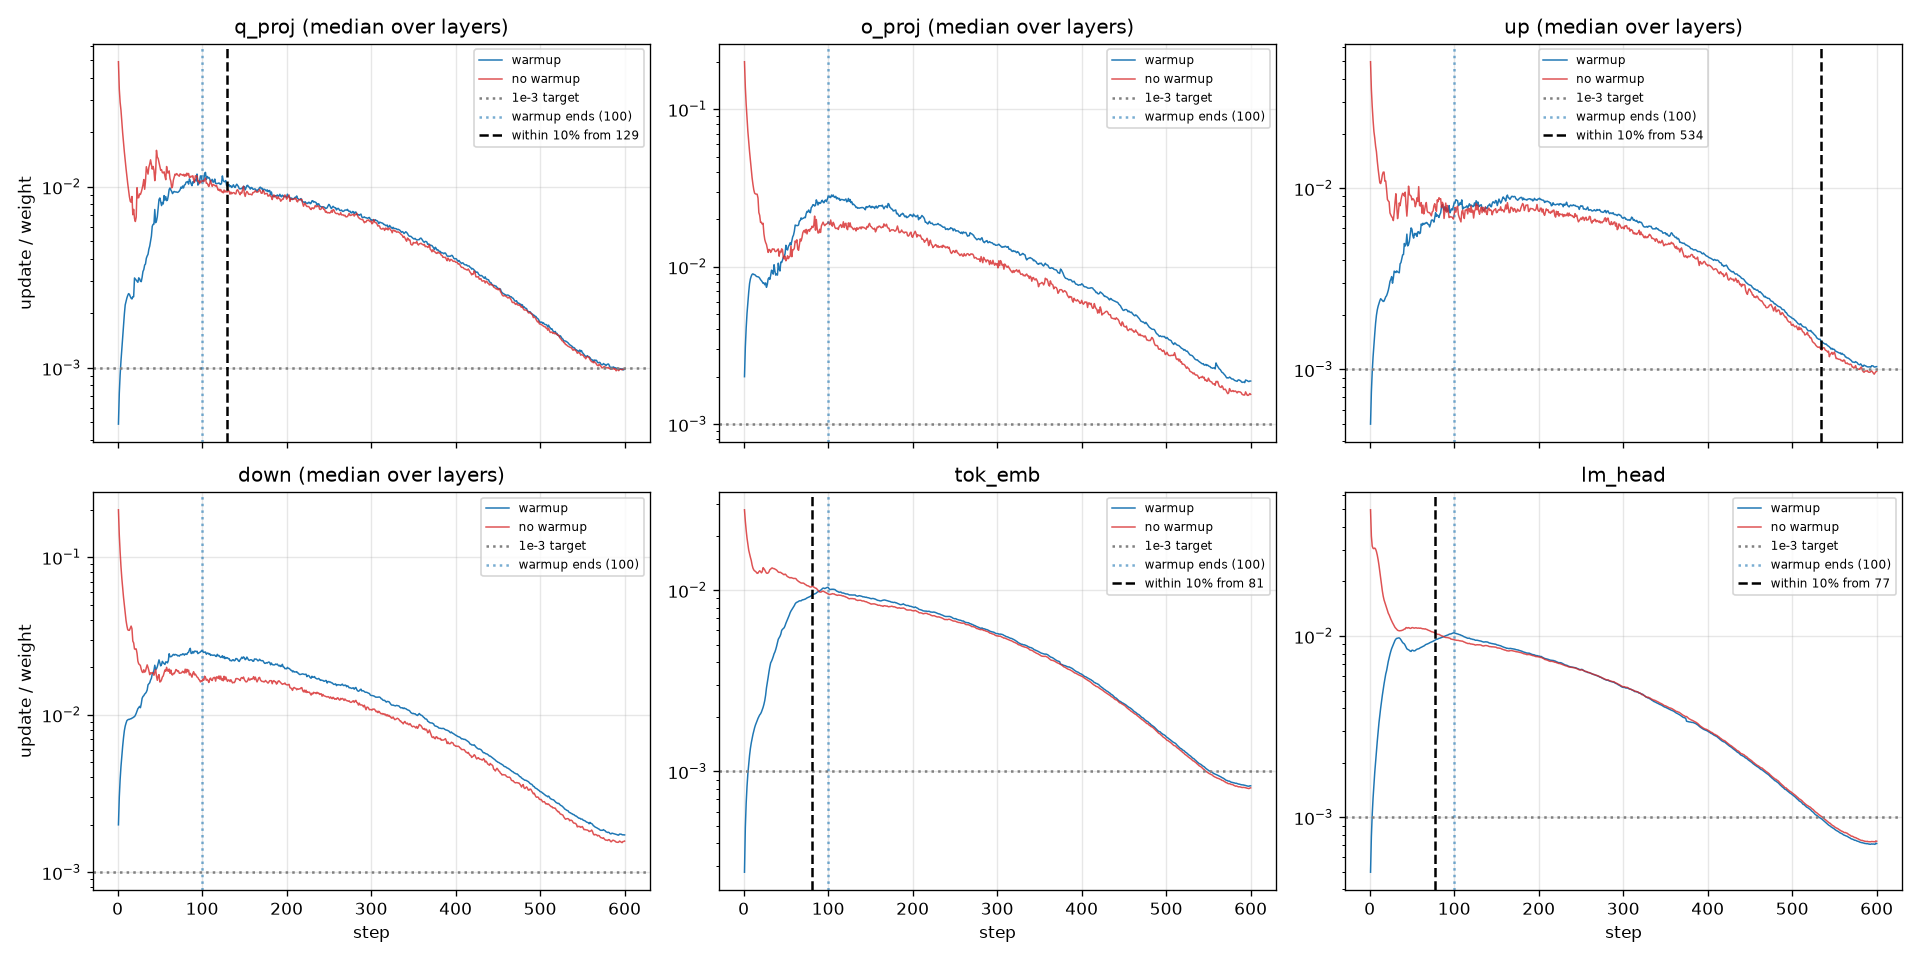

In [4]:
run("ratio", "s11_3_ratio.txt")
show("update_ratio.png")

## Task 4: Cosine vs WSD, stopped at step 200

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

4. COSINE vs WSD, BOTH PLANNED FOR 300 STEPS, COMPARED AT 200 (Task 4)
  peak lr 0.001, warmup 30 steps, both decay to 10% of peak.
  cosine_300: cosine over the whole run.  wsd_300: flat at peak, linear decay over the
  last 30 steps.  cosine_200: a run that KNEW it would stop at 200.
  Validation on 20 fixed batches every 25 steps; step 200 is one of them.

  RUN cosine_300  (lr at step 200: 3.77e-04)
    step        lr     loss     true    gnorm     val      ms    time
       0  3.33e-05   9.0867   9.0867    4.971  9.0889     229      1s
      25  8.67e-04   7.2400   7.2400    0.689  7.2295     124      4s
      50  9.88e-04   6.8175   6.8175    0.521  6.7623     105      7s
      75  9.40e-04   6.4489   6.4489    0.546  6.4603     105     10s
     100  8.59e-04   6.2265   6.2265    0.509  6.2648     108     13s
     125  7.52e-04   6.1814   6.1814    0.489  6.1362     109     16s
     150  6.28e-04   6.0070   6.0070   

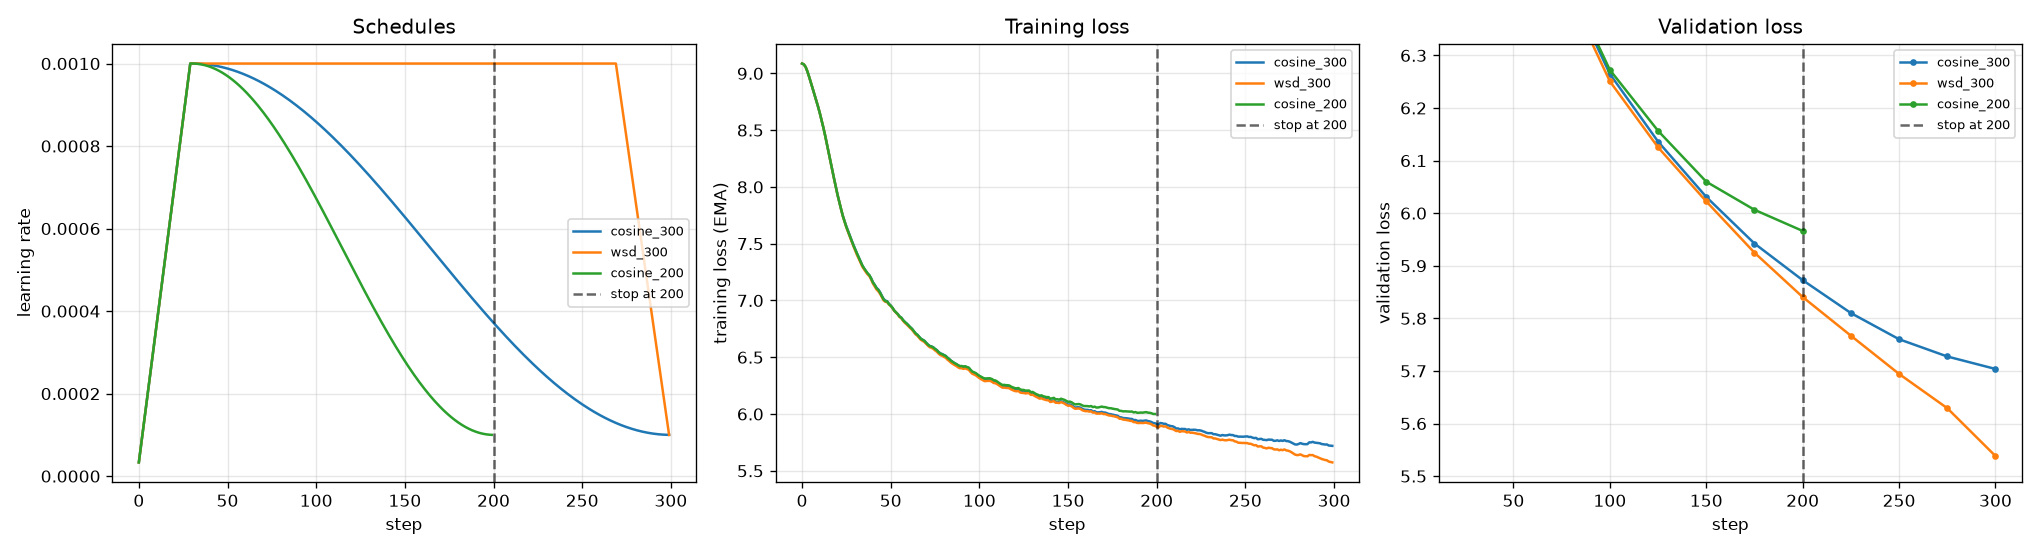

In [5]:
run("schedule", "s11_4_schedule.txt")
show("schedules.png")

## Task 5: Learning-rate sweep across widths

The longest section. Every finished run is appended to `runs/session11/sweep.csv`, so if the
kernel is interrupted, re-running this cell continues where it stopped.

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

5. LEARNING-RATE SWEEP ACROSS WIDTHS, AND AN ESTIMATE FOR 4,096 (Task 5)
  widths [256, 384, 512, 1024], 8 layers, head_dim 64, FFN ~8/3 D. Learning rates ['0.00025', '0.0005', '0.001', '0.002', '0.004', '0.008', '0.016']
  600 steps each = 4.9M tokens, warmup 100, cosine to 10%, AdamW (0.9, 0.95), wd 0.1, clip 1.0, same seed and batches for every run.
  Score = validation loss on 20 fixed batches at the end. Init is std 0.02 at every width
  (standard parameterisation, not muP), so the best lr is expected to move with width.

    width   256: heads  4, FFN   704,   10.6M parameters
    width   384: heads  6, FFN  1024,   20.5M parameters
    width   512: heads  8, FFN  1408,   34.1M parameters
    width  1024: heads 16, FFN  2752,  118.0M parameters
       0  2.50e-06   9.0497   9.0497    3.528  9.0566     249      1s
    width   256  lr  2.50e-04  val   5.6748   0.6 min (total 1 min, ~4 min left at this width)
       0  

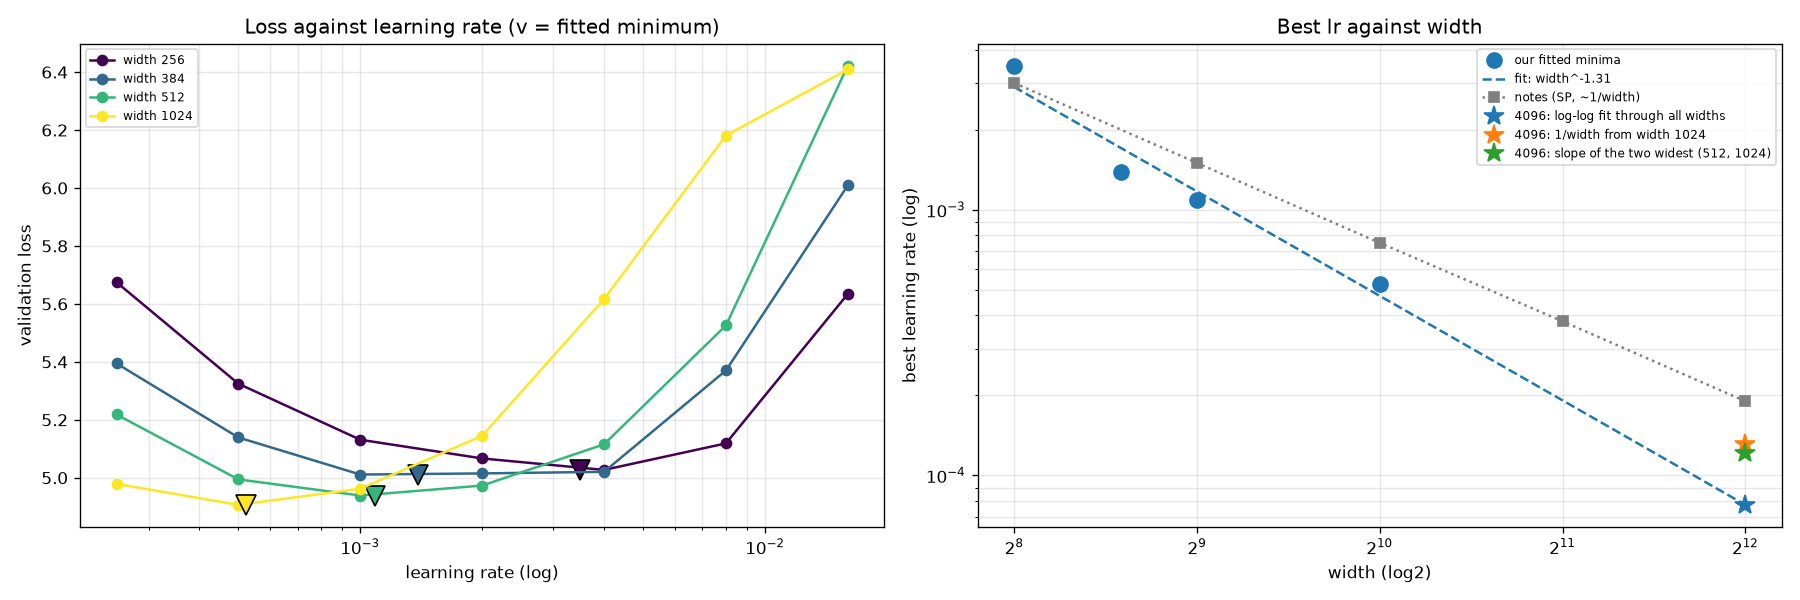

In [6]:
run("sweep", "s11_5_sweep.txt")
show("lr_sweep.png")